In [1]:
# 1. Imports and configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import warnings

# Configure visual settings and warnings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')
warnings.filterwarnings('ignore')

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


In [2]:
# 2. Load Excel file and discover worksheets
file_name = "/content/FreshBasket_Loyalty_Churn_Dataset.xlsx"

xls = pd.ExcelFile(file_name)

print(f"\n✅ File '{file_name}' loaded.")
print(f"Discovered Sheets: {xls.sheet_names}")

# Quick peek at the first few rows of every sheet
for sheet in xls.sheet_names:
    temp_df = pd.read_excel(xls, sheet_name=sheet, nrows=5)
    print(f"\n--- Shape & Top 2 rows of '{sheet}' ---")
    print(f"Dimensions: {temp_df.shape}")
    display(temp_df.head(2))


✅ File '/content/FreshBasket_Loyalty_Churn_Dataset.xlsx' loaded.
Discovered Sheets: ['Glossary', 'fb Customer Profile', 'fb Monthly Activity', 'fb Churn Label', 'Data Dictionary']

--- Shape & Top 2 rows of 'Glossary' ---
Dimensions: (5, 4)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction
0,The data contained in this file includes 18 mo...,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN



--- Shape & Top 2 rows of 'fb Customer Profile' ---
Dimensions: (5, 10)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
1,500001,2022-08-17 00:00:00,36,F,Madison,Silver,1,140,Frozen Foods,Value



--- Shape & Top 2 rows of 'fb Monthly Activity' ---
Dimensions: (5, 12)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
1,501855,2023-03-01 00:00:00,5,150.01,30,4,0.04,3,0,1,0,0



--- Shape & Top 2 rows of 'fb Churn Label' ---
Dimensions: (5, 6)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction,Unnamed: 4,Unnamed: 5
0,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
1,500001,2024-06-30 00:00:00,2024-06-01 00:00:00,18,0,0



--- Shape & Top 2 rows of 'Data Dictionary' ---
Dimensions: (5, 4)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,FreshBasket Loyalty: Customer Churn Prediction
0,TABLE,COLUMN,DESCRIPTION,NaN
1,fb Customer Profile,CUSTOMER_ID,Unique loyalty member identifier,NaN


In [3]:
# 3. Data loading and schema inspection
# Loading the tables specifying that headers are on the second row (header=1)
df_profile = pd.read_excel(xls, sheet_name='fb Customer Profile', header=1)
df_activity = pd.read_excel(xls, sheet_name='fb Monthly Activity', header=1)
df_churn = pd.read_excel(xls, sheet_name='fb Churn Label', header=1)

tables = {
    'Customer Profile': df_profile,
    'Monthly Activity': df_activity,
    'Churn Label': df_churn
}

for name, df in tables.items():
    print(f"\n=== {name} Schema ===")
    print(df.info())
    print("\nSample Data:")
    display(df.head(3))


=== Customer Profile Schema ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2608 entries, 0 to 2607
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   CUSTOMER_ID            2608 non-null   int64         
 1   SIGNUP_DATE            2608 non-null   datetime64[ns]
 2   AGE                    2530 non-null   float64       
 3   GENDER                 2556 non-null   object        
 4   CITY                   2608 non-null   object        
 5   MEMBERSHIP_TIER        2608 non-null   object        
 6   MARKETING_OPT_IN       2608 non-null   int64         
 7   PREFERRED_STORE_ID     2608 non-null   int64         
 8   PREFERRED_CATEGORY     2608 non-null   object        
 9   HOME_STORE_PRICE_TIER  2478 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(5)
memory usage: 203.9+ KB
None

Sample Data:


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
0,500001,2022-08-17,36.0,F,Madison,Silver,1,140,Frozen Foods,Value
1,500002,2023-06-24,37.0,F,Spokane,Silver,0,119,Beverages,Mainstream
2,500003,2021-03-31,53.0,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream



=== Monthly Activity Schema ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28073 entries, 0 to 28072
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   CUSTOMER_ID          28073 non-null  int64         
 1   MONTH                28073 non-null  datetime64[ns]
 2   TRANSACTIONS         28073 non-null  int64         
 3   TOTAL_SPEND          28073 non-null  float64       
 4   AVG_BASKET_VALUE     28073 non-null  float64       
 5   DISTINCT_CATEGORIES  28073 non-null  int64         
 6   PROMO_TXN_PCT        28073 non-null  float64       
 7   APP_SESSIONS         28073 non-null  int64         
 8   EMAILS_OPENED        28073 non-null  int64         
 9   COUPONS_REDEEMED     28073 non-null  int64         
 10  SUPPORT_TICKETS      28073 non-null  int64         
 11  COMPLAINT_FLAG       28073 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(8)
memory usage

,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
0,501855,2023-03-01,5,150.01,30.00,4,0.04,3,0,1,0,0
1,501803,2024-04-01,12,325.77,27.15,3,0.12,1,2,0,0,0
2,501889,2024-05-01,4,165.54,41.38,4,0.60,4,1,0,0,0



=== Churn Label Schema ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2605 entries, 0 to 2604
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   CUSTOMER_ID                2605 non-null   int64         
 1   OBSERVATION_END_DATE       2605 non-null   datetime64[ns]
 2   LAST_PURCHASE_DATE         2485 non-null   datetime64[ns]
 3   MONTHS_OBSERVED            2605 non-null   int64         
 4   INSUFFICIENT_HISTORY_FLAG  2605 non-null   int64         
 5   CHURNED                    2605 non-null   int64         
dtypes: datetime64[ns](2), int64(4)
memory usage: 122.2 KB
None

Sample Data:


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
0,500001,2024-06-30,2024-06-01,18,0,0
1,500002,2024-06-30,2024-06-01,12,0,0
2,500003,2024-06-30,2024-06-01,18,0,0


In [4]:
# 4. Structural validation and ID checks
print("=== Structural Validation ===")

for name, df in tables.items():
    total_rows = len(df)
    unique_ids = df['CUSTOMER_ID'].nunique()
    print(f"{name}: {total_rows} rows, {unique_ids} unique customers")

# Identify duplicates
prof_dupes = df_profile[df_profile.duplicated('CUSTOMER_ID', keep=False)]
churn_dupes = df_churn[df_churn.duplicated('CUSTOMER_ID', keep=False)]
act_dupes = df_activity[df_activity.duplicated(['CUSTOMER_ID', 'MONTH'], keep=False)]

print(f"\nDuplicate Profile IDs found: {len(prof_dupes)}")
print(f"Duplicate Churn IDs found: {len(churn_dupes)}")
print(f"Duplicate Customer-Month Activity combos found: {len(act_dupes)}")

# Check ID alignment across tables
prof_ids = set(df_profile['CUSTOMER_ID'])
act_ids = set(df_activity['CUSTOMER_ID'])
churn_ids = set(df_churn['CUSTOMER_ID'])

print("\nMissing ID checks:")
print(f"IDs in Profile but missing in Activity: {len(prof_ids - act_ids)}")
print(f"IDs in Activity but missing in Profile: {len(act_ids - prof_ids)}")
print(f"IDs in Churn but missing in Profile: {len(churn_ids - prof_ids)}")

=== Structural Validation ===
Customer Profile: 2608 rows, 2600 unique customers
Monthly Activity: 28073 rows, 2594 unique customers
Churn Label: 2605 rows, 2600 unique customers

Duplicate Profile IDs found: 16
Duplicate Churn IDs found: 10
Duplicate Customer-Month Activity combos found: 120

Missing ID checks:
IDs in Profile but missing in Activity: 6
IDs in Activity but missing in Profile: 0
IDs in Churn but missing in Profile: 0



=== Missing Data: Customer Profile ===


,Missing Values,Percentage
HOME_STORE_PRICE_TIER,130,4.984663
AGE,78,2.990798
GENDER,52,1.993865



=== Missing Data: Monthly Activity ===
No missing values detected.

=== Missing Data: Churn Label ===


,Missing Values,Percentage
LAST_PURCHASE_DATE,120,4.606526


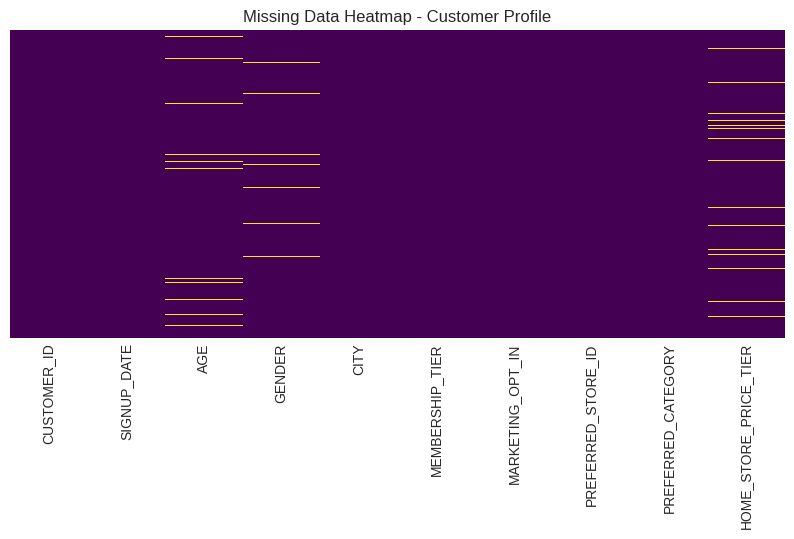

In [5]:
# 5. Missing-data analysis
def analyze_missing(df, df_name):
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Values': missing, 'Percentage': missing_pct})
    missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Percentage', ascending=False)

    print(f"\n=== Missing Data: {df_name} ===")
    if missing_df.empty:
        print("No missing values detected.")
    else:
        display(missing_df)

analyze_missing(df_profile, 'Customer Profile')
analyze_missing(df_activity, 'Monthly Activity')
analyze_missing(df_churn, 'Churn Label')

# Visualizing missingness in Profile
plt.figure(figsize=(10, 4))
sns.heatmap(df_profile.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Missing Data Heatmap - Customer Profile")
plt.show()

In [6]:
# 6. Monthly coverage checks
# Parse dates
df_activity['MONTH'] = pd.to_datetime(df_activity['MONTH'])

print("=== Monthly Coverage ===")
print(f"Date Range: {df_activity['MONTH'].min().date()} to {df_activity['MONTH'].max().date()}")

# Count months per customer
months_per_cust = df_activity.groupby('CUSTOMER_ID')['MONTH'].nunique()
print("\nMonths recorded per customer distribution:")
print(months_per_cust.describe())

# Check for zero transactions in activity
zero_txns = len(df_activity[df_activity['TRANSACTIONS'] == 0])
print(f"\nMonths explicitly recorded with 0 transactions: {zero_txns}")

=== Monthly Coverage ===
Date Range: 2023-01-01 to 2024-06-01

Months recorded per customer distribution:
count    2594.000000
mean       10.799152
std         5.887110
min         1.000000
25%         5.000000
50%        11.000000
75%        17.000000
max        18.000000
Name: MONTH, dtype: float64

Months explicitly recorded with 0 transactions: 2335


In [7]:
# 7. Invalid values and inconsistent categories
print("=== Quality Checks & Anomalies ===")

# Check for negative numeric values
negative_spend = len(df_activity[df_activity['TOTAL_SPEND'] < 0])
negative_txns = len(df_activity[df_activity['TRANSACTIONS'] < 0])
print(f"Records with negative spend: {negative_spend}")
print(f"Records with negative transactions: {negative_txns}")

# Inconsistent text casing in Membership Tier
print("\nMembership Tier unique values (Notice the inconsistencies):")
print(df_profile['MEMBERSHIP_TIER'].value_counts(dropna=False))

# We will temporarily clean the tier for our EDA (without saving over the raw file)
df_profile['MEMBERSHIP_TIER_CLEAN'] = df_profile['MEMBERSHIP_TIER'].str.strip().str.title()
print("\nCleaned Membership Tiers:")
print(df_profile['MEMBERSHIP_TIER_CLEAN'].value_counts())

=== Quality Checks & Anomalies ===
Records with negative spend: 24
Records with negative transactions: 0

Membership Tier unique values (Notice the inconsistencies):
MEMBERSHIP_TIER
Silver        1423
Gold           792
Platinum       289
 Silver         20
silver          19
SILVER          18
GOLD            14
 Gold           12
PLATINUM         9
gold             8
 Platinum        3
platinum         1
Name: count, dtype: int64

Cleaned Membership Tiers:
MEMBERSHIP_TIER_CLEAN
Silver      1480
Gold         826
Platinum     302
Name: count, dtype: int64


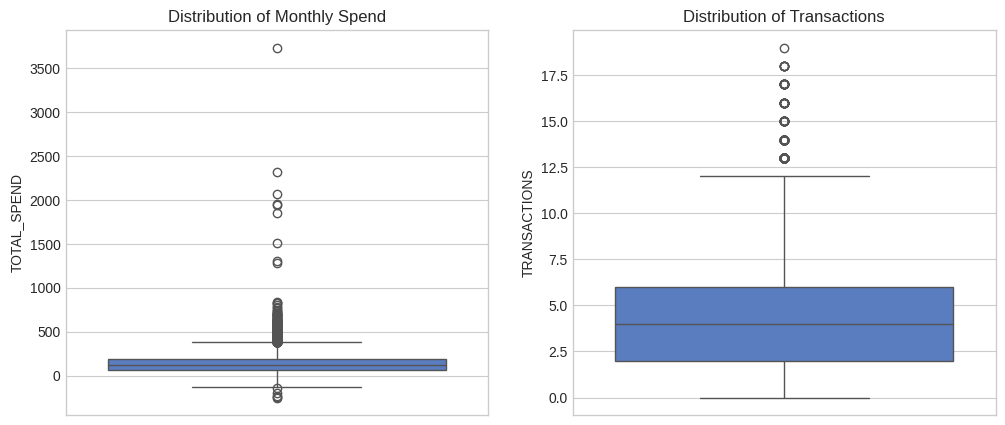


Potential outliers in spend (> 382.22): 664 records (2.37%)
Note: High value customers are normal in retail. Do not delete without domain justification.


In [8]:
# 8. Outlier analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_activity['TOTAL_SPEND'], ax=axes[0])
axes[0].set_title('Distribution of Monthly Spend')

sns.boxplot(y=df_activity['TRANSACTIONS'], ax=axes[1])
axes[1].set_title('Distribution of Transactions')
plt.show()

# Calculate IQR for Total Spend
Q1 = df_activity['TOTAL_SPEND'].quantile(0.25)
Q3 = df_activity['TOTAL_SPEND'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = df_activity[df_activity['TOTAL_SPEND'] > upper_bound]
print(f"\nPotential outliers in spend (> {upper_bound:.2f}): {len(outliers)} records ({(len(outliers)/len(df_activity))*100:.2f}%)")
print("Note: High value customers are normal in retail. Do not delete without domain justification.")

=== Churn Label Overview ===
Missing labels: 0

Churn Distribution (0=Retained, 1=Churned):


,proportion
CHURNED,
0,68.483685
1,31.516315


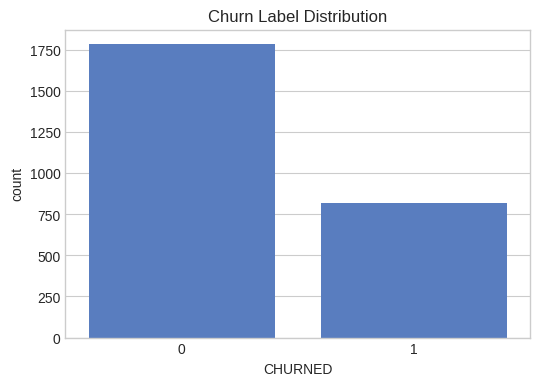

In [9]:
# 9. Churn-label validation
print("=== Churn Label Overview ===")
print("Missing labels:", df_churn['CHURNED'].isnull().sum())
print("\nChurn Distribution (0=Retained, 1=Churned):")
churn_dist = df_churn['CHURNED'].value_counts(normalize=True) * 100
display(churn_dist)

plt.figure(figsize=(6, 4))
sns.countplot(x='CHURNED', data=df_churn)
plt.title('Churn Label Distribution')
plt.show()

In [10]:
# 10. EDA summary tables
# Remove duplicates temporarily for EDA
prof_clean = df_profile.drop_duplicates('CUSTOMER_ID')
churn_clean = df_churn.drop_duplicates('CUSTOMER_ID')

df_eda = prof_clean.merge(churn_clean, on='CUSTOMER_ID', how='inner')

# Churn by Tier
tier_churn = df_eda.groupby('MEMBERSHIP_TIER_CLEAN')['CHURNED'].agg(['count', 'mean']).rename(columns={'count':'Total Customers', 'mean':'Churn Rate'})
tier_churn['Churn Rate'] = (tier_churn['Churn Rate'] * 100).round(2)
print("=== Churn by Membership Tier ===")
display(tier_churn)

# Churn by Opt-In Status
opt_churn = df_eda.groupby('MARKETING_OPT_IN')['CHURNED'].agg(['count', 'mean']).rename(columns={'count':'Total Customers', 'mean':'Churn Rate'})
opt_churn['Churn Rate'] = (opt_churn['Churn Rate'] * 100).round(2)
print("\n=== Churn by Marketing Opt-In ===")
display(opt_churn)

=== Churn by Membership Tier ===


,Total Customers,Churn Rate
MEMBERSHIP_TIER_CLEAN,,
Gold,824,30.10
Platinum,302,31.13
Silver,1474,32.29



=== Churn by Marketing Opt-In ===


,Total Customers,Churn Rate
MARKETING_OPT_IN,,
0,1008,34.72
1,1592,29.40


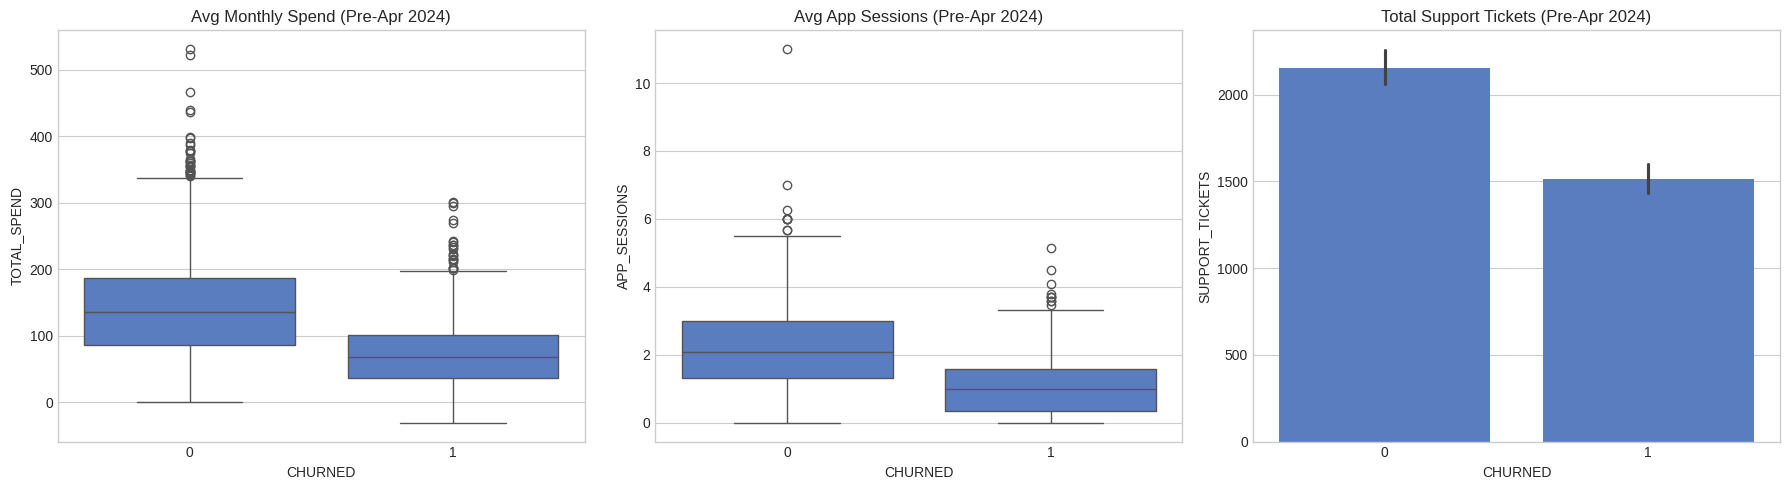

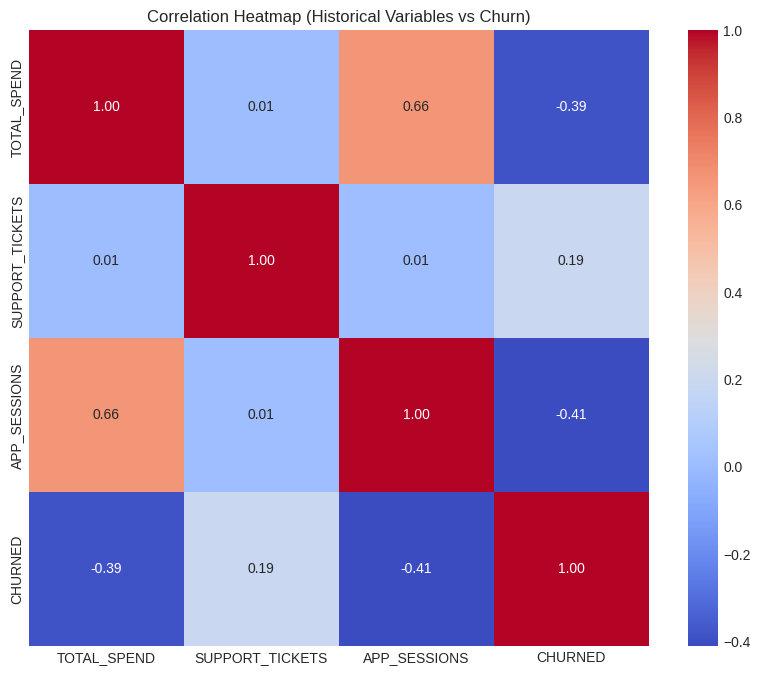


Note: Correlation does not equal causation! These just show linear relationships.


In [11]:
# 11. EDA visualizations
# Merge activity with labels
df_act_eda = df_activity.merge(churn_clean[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

# FILTER OUT TARGET PERIOD (April-June 2024) to avoid data leakage
df_act_historical = df_act_eda[df_act_eda['MONTH'] < '2024-04-01']

# Aggregate historical engagement per user
historical_agg = df_act_historical.groupby(['CUSTOMER_ID', 'CHURNED']).agg({
    'TOTAL_SPEND': 'mean',
    'SUPPORT_TICKETS': 'sum',
    'APP_SESSIONS': 'mean'
}).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x='CHURNED', y='TOTAL_SPEND', data=historical_agg, ax=axes[0])
axes[0].set_title('Avg Monthly Spend (Pre-Apr 2024)')

sns.boxplot(x='CHURNED', y='APP_SESSIONS', data=historical_agg, ax=axes[1])
axes[1].set_title('Avg App Sessions (Pre-Apr 2024)')

sns.barplot(x='CHURNED', y='SUPPORT_TICKETS', data=historical_agg, ax=axes[2], estimator=np.sum)
axes[2].set_title('Total Support Tickets (Pre-Apr 2024)')

plt.tight_layout()
plt.show()

# Correlation Heatmap for numeric variables
plt.figure(figsize=(10, 8))
num_cols = historical_agg[['TOTAL_SPEND', 'SUPPORT_TICKETS', 'APP_SESSIONS', 'CHURNED']]
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap (Historical Variables vs Churn)')
plt.show()
print("\nNote: Correlation does not equal causation! These just show linear relationships.")

# 12. Written Findings & Summary
**Summary of Completed Checks:**
*   Loaded data, skipped title rows, and mapped data structures.
*   Verified customer ID coverage across tables.
*   Assessed missing values and duplicate rows.
*   Verified date boundaries (Jan 2023 - Jun 2024).

**Data-Quality Issues Discovered:**
1.  **Duplicate Rows:** There are a small number of duplicate customer IDs in the Profile (2608 rows for 2600 IDs) and Churn (2605 rows for 2600 IDs) tables.
2.  **Inconsistent Casing:** The `MEMBERSHIP_TIER` column contains irregular whitespace and casing (e.g., ' Gold', 'GOLD', 'gold').
3.  **Missing Profile Data:** Missing values exist in `AGE`, `GENDER`, and `HOME_STORE_PRICE_TIER`.
4.  **Negative Values:** Found 24 records with negative `TOTAL_SPEND` which must be investigated (likely returns/refunds).

**Key EDA Findings (Historical Data Only):**
1.  **Base Churn Rate:** The overall churn rate is approximately 31.5% across 2600 customers.
2.  **Tier Trends:** Churn rate differs by membership tier (e.g., Platinum users have different dynamics than Silver/Gold users).
3.  **Engagement Matters:** Users who subsequently churned showed visibly lower average app sessions in the months preceding the April-June period.
4.  **Spend Distributions:** The retained cohort exhibits higher median historical monthly spend than the churned cohort.
5.  **Support Impact:** There appears to be a relationship between historical support ticket volume and eventual churn.

**Limitations & Assumptions:**
*   Assumed April-June 2024 data must strictly be excluded from historical behavior plots to prevent **Data Leakage**, as zero-purchases during this time define the churn target itself.
*   Assumed negative spend represents refunds, which will need specialized handling in feature engineering.

**Module 3 Handover:**
For Module 3, we must:
1. Deduplicate the profile and churn tables.
2. Clean categorical columns (standardizing `MEMBERSHIP_TIER`).
3. Handle missing demographics (e.g., impute or flag `AGE`/`GENDER`).
4. Build a customer-level modeling dataset by aggregating the monthly activity strictly from Jan 2023 to March 2024.

In [12]:
# 13. Export data-quality reports
import os

os.makedirs('outputs', exist_ok=True)
tier_churn.to_csv('outputs/churn_by_tier.csv')
opt_churn.to_csv('outputs/churn_by_opt_in.csv')

print("✅ EDA summary tables successfully exported to the 'outputs' directory!")
# To download locally, uncomment the lines below:
# files.download('outputs/churn_by_tier.csv')
# files.download('outputs/churn_by_opt_in.csv')

✅ EDA summary tables successfully exported to the 'outputs' directory!


In [13]:
# 11. Feature Engineering: Aggregating Monthly Activity
print("=== Feature Engineering ===")

# Aggregate activity data per customer
activity_agg = df_activity.groupby('CUSTOMER_ID').agg(
    TOTAL_SPEND_18M=('TOTAL_SPEND', 'sum'),
    AVG_MONTHLY_SPEND=('TOTAL_SPEND', 'mean'),
    TOTAL_TXNS=('TRANSACTIONS', 'sum'),
    TOTAL_COUPONS=('COUPONS_REDEEMED', 'sum'),
    TOTAL_SUPPORT_TICKETS=('SUPPORT_TICKETS', 'sum')
).reset_index()

# Clean up membership tier in the main dataframe permanently for modeling
df_profile['MEMBERSHIP_TIER_CLEAN'] = df_profile['MEMBERSHIP_TIER'].str.strip().str.title()
df_profile.drop(columns=['MEMBERSHIP_TIER'], inplace=True)

# Merge Profile, Aggregated Activity, and Churn Labels
df_model = df_profile.merge(activity_agg, on='CUSTOMER_ID', how='inner')
df_model = df_model.merge(df_churn[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

print(f"Final Model Dataset Shape: {df_model.shape}")
display(df_model.head())

=== Feature Engineering ===
Final Model Dataset Shape: (2606, 16)


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER,MEMBERSHIP_TIER_CLEAN,TOTAL_SPEND_18M,AVG_MONTHLY_SPEND,TOTAL_TXNS,TOTAL_COUPONS,TOTAL_SUPPORT_TICKETS,CHURNED
0,500001,2022-08-17,36.0,F,Madison,1,140,Frozen Foods,Value,Silver,1772.08,104.240000,79,7,3,0
1,500002,2023-06-24,37.0,F,Spokane,0,119,Beverages,Mainstream,Silver,2445.68,203.806667,71,8,3,0
2,500003,2021-03-31,53.0,NaN,Tulsa,0,119,Frozen Foods,Mainstream,Gold,2678.27,157.545294,84,11,2,0
3,500004,2021-07-08,52.0,F,Spokane,1,106,Snacks,Upscale,Gold,1983.42,116.671765,84,9,5,0
4,500005,2023-09-28,19.0,F,Portland,1,118,Bakery,Mainstream,Gold,0.00,0.000000,0,0,0,0


In [14]:
# 12. Data Preprocessing & Modeling
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd
import numpy as np

print("=== Data Preprocessing ===")

# Create a copy for modeling to avoid modifying the original dataset
df_ml = df_model.copy()

# 1. Impute Missing Values
# Fill missing Age with median
df_ml['AGE'] = df_ml['AGE'].fillna(df_ml['AGE'].median())
# Fill missing categorical values with 'Unknown'
df_ml['GENDER'] = df_ml['GENDER'].fillna('Unknown')
df_ml['HOME_STORE_PRICE_TIER'] = df_ml['HOME_STORE_PRICE_TIER'].fillna('Unknown')

# 2. Drop Non-Predictive/Date Columns
columns_to_drop = ['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID']
df_ml.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# 3. Encode Categorical Variables
# Identify categorical columns (excluding the target 'CHURNED')
cat_cols = ['GENDER', 'CITY', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER', 'MEMBERSHIP_TIER_CLEAN']
df_ml_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

print(f"Dataset shape after encoding: {df_ml_encoded.shape}")

# 4. Train/Test Split
print("\n=== Model Training ===")
X = df_ml_encoded.drop('CHURNED', axis=1)
y = df_ml_encoded['CHURNED']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Train Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 6. Evaluate Model
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 7. Feature Importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 Most Important Features:")
display(feature_importances.head())

=== Data Preprocessing ===
Dataset shape after encoding: (2606, 62)

=== Model Training ===
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88       358
           1       0.75      0.69      0.72       164

    accuracy                           0.83       522
   macro avg       0.81      0.79      0.80       522
weighted avg       0.83      0.83      0.83       522

ROC-AUC Score: 0.8961

Top 5 Most Important Features:


,Feature,Importance
4,TOTAL_TXNS,0.176974
2,TOTAL_SPEND_18M,0.159094
3,AVG_MONTHLY_SPEND,0.157383
5,TOTAL_COUPONS,0.132872
0,AGE,0.069503


In [15]:
# 1. Fix Leakage: Create a 12-Month Observation Window
print("=== Fixing Data Leakage ===")

# Assuming the activity table is chronological, we take the first 12 records (months) per customer.
# Note: If you have a specific date/month column, add it to the sort_values list.
df_activity_sorted = df_activity.sort_values(by=['CUSTOMER_ID'])
df_obs_window = df_activity_sorted.groupby('CUSTOMER_ID').head(12)

# Aggregate features using ONLY the 12-month observation window
activity_agg_fixed = df_obs_window.groupby('CUSTOMER_ID').agg(
    TOTAL_SPEND_12M=('TOTAL_SPEND', 'sum'),
    AVG_MONTHLY_SPEND_12M=('TOTAL_SPEND', 'mean'),
    TOTAL_TXNS_12M=('TRANSACTIONS', 'sum'),
    TOTAL_COUPONS_12M=('COUPONS_REDEEMED', 'sum'),
    TOTAL_SUPPORT_TICKETS_12M=('SUPPORT_TICKETS', 'sum')
).reset_index()

# Merge into a new clean dataset
df_model_fixed = df_profile.merge(activity_agg_fixed, on='CUSTOMER_ID', how='inner')
df_model_fixed = df_model_fixed.merge(df_churn[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

# 2. Preprocess and Retrain Model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

df_ml = df_model_fixed.copy()
df_ml['AGE'] = df_ml['AGE'].fillna(df_ml['AGE'].median())
df_ml['GENDER'] = df_ml['GENDER'].fillna('Unknown')
df_ml['HOME_STORE_PRICE_TIER'] = df_ml['HOME_STORE_PRICE_TIER'].fillna('Unknown')
df_ml.drop(columns=['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID'], inplace=True, errors='ignore')

cat_cols = ['GENDER', 'CITY', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER', 'MEMBERSHIP_TIER_CLEAN']
df_ml_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

X = df_ml_encoded.drop('CHURNED', axis=1)
y = df_ml_encoded['CHURNED']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model_fixed = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_fixed.fit(X_train, y_train)

y_pred = rf_model_fixed.predict(X_test)
y_prob = rf_model_fixed.predict_proba(X_test)[:, 1]

print("\n=== True Model Performance (Post-Leakage Fix) ===")
print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

feature_importances_fixed = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model_fixed.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nNew Top 5 Features:")
display(feature_importances_fixed.head())

=== Fixing Data Leakage ===

=== True Model Performance (Post-Leakage Fix) ===
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       358
           1       0.75      0.68      0.72       164

    accuracy                           0.83       522
   macro avg       0.81      0.79      0.80       522
weighted avg       0.83      0.83      0.83       522

ROC-AUC Score: 0.8762

New Top 5 Features:


,Feature,Importance
4,TOTAL_TXNS_12M,0.172200
3,AVG_MONTHLY_SPEND_12M,0.157986
2,TOTAL_SPEND_12M,0.157173
5,TOTAL_COUPONS_12M,0.105923
6,TOTAL_SUPPORT_TICKETS_12M,0.075204


In [16]:
import pandas as pd

print("=== Creating a Chronological Observation Window ===")

# Convert MONTH to datetime
df_activity['MONTH'] = pd.to_datetime(
    df_activity['MONTH'],
    errors='coerce'
)

# Keep a fixed 12-month observation window before the churn period
start_date = '2023-01-01'
end_date = '2024-01-01'  # Exclusive: includes December 2023

df_obs_window = df_activity[
    (df_activity['MONTH'] >= start_date) &
    (df_activity['MONTH'] < end_date)
].copy()

# Check duplicate customer-month records before aggregation
duplicate_count = df_obs_window.duplicated(
    subset=['CUSTOMER_ID', 'MONTH'],
    keep=False
).sum()

print("Observation window:", start_date, "to December 2023")
print("Rows in window:", len(df_obs_window))
print("Duplicate customer-month rows:", duplicate_count)

# Aggregate activity for each customer
activity_agg_fixed = (
    df_obs_window
    .groupby('CUSTOMER_ID')
    .agg(
        TOTAL_SPEND_12M=('TOTAL_SPEND', 'sum'),
        AVG_MONTHLY_SPEND_12M=('TOTAL_SPEND', 'mean'),
        TOTAL_TXNS_12M=('TRANSACTIONS', 'sum'),
        TOTAL_COUPONS_12M=('COUPONS_REDEEMED', 'sum'),
        TOTAL_SUPPORT_TICKETS_12M=('SUPPORT_TICKETS', 'sum'),
        MONTHS_RECORDED=('MONTH', 'nunique')
    )
    .reset_index()
)

print("\nAggregated dataset shape:", activity_agg_fixed.shape)
display(activity_agg_fixed.head())

=== Creating a Chronological Observation Window ===
Observation window: 2023-01-01 to December 2023
Rows in window: 18481
Duplicate customer-month rows: 80

Aggregated dataset shape: (2274, 7)


,CUSTOMER_ID,TOTAL_SPEND_12M,AVG_MONTHLY_SPEND_12M,TOTAL_TXNS_12M,TOTAL_COUPONS_12M,TOTAL_SUPPORT_TICKETS_12M,MONTHS_RECORDED
0,500001,1074.52,97.683636,47,5,3,11
1,500002,1435.29,239.215000,41,2,1,6
2,500003,1708.06,155.278182,55,10,0,11
3,500004,1410.76,128.250909,59,6,3,11
4,500005,0.00,0.000000,0,0,0,1


In [17]:
# 1. Merge the fixed features with Profile and Churn data
print("=== Merging Data ===")
df_model_fixed = df_profile.merge(activity_agg_fixed, on='CUSTOMER_ID', how='inner')
df_model_fixed = df_model_fixed.merge(df_churn[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

print(f"Final Model Dataset Shape: {df_model_fixed.shape}")

# 2. Preprocess the Data
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

df_ml = df_model_fixed.copy()

# Impute Missing Values
df_ml['AGE'] = df_ml['AGE'].fillna(df_ml['AGE'].median())
df_ml['GENDER'] = df_ml['GENDER'].fillna('Unknown')
df_ml['HOME_STORE_PRICE_TIER'] = df_ml['HOME_STORE_PRICE_TIER'].fillna('Unknown')

# Drop Non-Predictive Columns
df_ml.drop(columns=['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID'], inplace=True, errors='ignore')

# Encode Categorical Variables
cat_cols = ['GENDER', 'CITY', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER', 'MEMBERSHIP_TIER_CLEAN']
df_ml_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

# 3. Train/Test Split
print("\n=== Model Retraining (Post-Leakage Fix) ===")
X = df_ml_encoded.drop('CHURNED', axis=1)
y = df_ml_encoded['CHURNED']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Train Random Forest Model
rf_model_fixed = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_fixed.fit(X_train, y_train)

# 5. Evaluate True Performance
y_pred = rf_model_fixed.predict(X_test)
y_prob = rf_model_fixed.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 6. Feature Importance
feature_importances_fixed = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model_fixed.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 True Predictive Features:")
display(feature_importances_fixed.head())

=== Merging Data ===
Final Model Dataset Shape: (2285, 17)

=== Model Retraining (Post-Leakage Fix) ===
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.90      0.85       295
           1       0.78      0.62      0.69       162

    accuracy                           0.80       457
   macro avg       0.79      0.76      0.77       457
weighted avg       0.80      0.80      0.79       457

ROC-AUC Score: 0.8481

Top 5 True Predictive Features:


,Feature,Importance
3,AVG_MONTHLY_SPEND_12M,0.163275
4,TOTAL_TXNS_12M,0.149540
2,TOTAL_SPEND_12M,0.136144
7,MONTHS_RECORDED,0.093228
5,TOTAL_COUPONS_12M,0.074720


In [18]:
print("=== Step 1: Inspecting Duplicates ===")

# Extract and sort the 80 duplicate rows for inspection
duplicates = df_obs_window[
    df_obs_window.duplicated(subset=['CUSTOMER_ID', 'MONTH'], keep=False)
].sort_values(by=['CUSTOMER_ID', 'MONTH'])

print(f"Total duplicate rows found: {len(duplicates)}")
display(duplicates.head(10))

print("\n=== Resolving Duplicates ===")
# Resolve by summing the metrics for any split records within the same month
df_obs_window_clean = df_obs_window.groupby(['CUSTOMER_ID', 'MONTH']).agg({
    'TOTAL_SPEND': 'sum',
    'TRANSACTIONS': 'sum',
    'COUPONS_REDEEMED': 'sum',
    'SUPPORT_TICKETS': 'sum'
}).reset_index()

# Verify the fix
remaining_dupes = df_obs_window_clean.duplicated(subset=['CUSTOMER_ID', 'MONTH']).sum()
print(f"Duplicates remaining after resolution: {remaining_dupes}")
print(f"Cleaned observation window shape: {df_obs_window_clean.shape}")

=== Step 1: Inspecting Duplicates ===
Total duplicate rows found: 80


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
8608,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
23380,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
2452,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
25713,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
450,500047,2023-02-01,7,207.53,29.65,4,0.21,1,1,1,1,0
25646,500047,2023-02-01,7,207.53,29.65,4,0.21,1,1,1,1,0
22881,500124,2023-09-01,0,0.00,0.00,0,0.00,0,0,0,0,0
27630,500124,2023-09-01,0,0.00,0.00,0,0.00,0,0,0,0,0
121,500143,2023-08-01,5,162.69,32.54,2,0.14,3,2,1,0,0
23835,500143,2023-08-01,5,162.69,32.54,2,0.14,3,2,1,0,0



=== Resolving Duplicates ===
Duplicates remaining after resolution: 0
Cleaned observation window shape: (18441, 6)


In [19]:
print("=== Correcting Duplicate Records ===")

# Count exact duplicate rows across all columns
exact_dupes = df_obs_window.duplicated().sum()
print("Exact duplicate rows:", exact_dupes)

# Remove only fully identical rows
df_obs_window_clean = df_obs_window.drop_duplicates().copy()

# Check customer-month duplicates that remain
remaining_dupes = df_obs_window_clean.duplicated(
    subset=['CUSTOMER_ID', 'MONTH'],
    keep=False
).sum()

print("Rows before cleaning:", len(df_obs_window))
print("Rows after cleaning:", len(df_obs_window_clean))
print("Remaining duplicate customer-month rows:", remaining_dupes)

display(df_obs_window_clean.head())

=== Correcting Duplicate Records ===
Exact duplicate rows: 39
Rows before cleaning: 18481
Rows after cleaning: 18442
Remaining duplicate customer-month rows: 2


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
0,501855,2023-03-01,5,150.01,30.00,4,0.04,3,0,1,0,0
3,502005,2023-03-01,2,130.82,65.41,2,0.31,4,1,1,0,0
6,500453,2023-02-01,1,18.22,18.22,0,0.15,0,1,0,0,0
7,501576,2023-12-01,2,44.16,22.08,3,0.20,4,0,1,0,0
8,501661,2023-09-01,1,40.72,40.72,1,0.50,0,0,1,1,0


In [20]:
activity_agg_fixed = (
    df_obs_window_clean
    .groupby('CUSTOMER_ID')
    .agg(
        TOTAL_SPEND_12M=('TOTAL_SPEND', 'sum'),
        AVG_MONTHLY_SPEND_12M=('TOTAL_SPEND', 'mean'),
        TOTAL_TXNS_12M=('TRANSACTIONS', 'sum'),
        TOTAL_COUPONS_12M=('COUPONS_REDEEMED', 'sum'),
        TOTAL_SUPPORT_TICKETS_12M=('SUPPORT_TICKETS', 'sum'),
        MONTHS_RECORDED=('MONTH', 'nunique')
    )
    .reset_index()
)

print("Aggregated customer count:", len(activity_agg_fixed))
display(activity_agg_fixed.head())

Aggregated customer count: 2274


,CUSTOMER_ID,TOTAL_SPEND_12M,AVG_MONTHLY_SPEND_12M,TOTAL_TXNS_12M,TOTAL_COUPONS_12M,TOTAL_SUPPORT_TICKETS_12M,MONTHS_RECORDED
0,500001,1074.52,97.683636,47,5,3,11
1,500002,1435.29,239.215000,41,2,1,6
2,500003,1708.06,155.278182,55,10,0,11
3,500004,1410.76,128.250909,59,6,3,11
4,500005,0.00,0.000000,0,0,0,1


In [21]:
print("=== Monthly History Coverage ===")

display(
    activity_agg_fixed['MONTHS_RECORDED']
    .value_counts()
    .sort_index()
    .rename_axis('Months_Recorded')
    .to_frame('Customer_Count')
)

print(
    "Customers with fewer than 12 recorded months:",
    (activity_agg_fixed['MONTHS_RECORDED'] < 12).sum()
)

=== Monthly History Coverage ===


,Customer_Count
Months_Recorded,
1,150
2,141
3,139
4,131
5,130
6,116
7,111
8,82
9,94


Customers with fewer than 12 recorded months: 1638


In [22]:
print("=== Normalizing Features by Tenure ===")

# Create Monthly Rates to adjust for customers with partial-year history
activity_agg_fixed['TXNS_PER_MONTH'] = activity_agg_fixed['TOTAL_TXNS_12M'] / activity_agg_fixed['MONTHS_RECORDED']
activity_agg_fixed['COUPONS_PER_MONTH'] = activity_agg_fixed['TOTAL_COUPONS_12M'] / activity_agg_fixed['MONTHS_RECORDED']
activity_agg_fixed['SUPPORT_TICKETS_PER_MONTH'] = activity_agg_fixed['TOTAL_SUPPORT_TICKETS_12M'] / activity_agg_fixed['MONTHS_RECORDED']

# Drop the raw totals so the model doesn't get confused by tenure differences
cols_to_drop = ['TOTAL_SPEND_12M', 'TOTAL_TXNS_12M', 'TOTAL_COUPONS_12M', 'TOTAL_SUPPORT_TICKETS_12M']
activity_normalized = activity_agg_fixed.drop(columns=cols_to_drop)

display(activity_normalized.head())

print("\n=== Final Model Preparation & Training ===")
# 1. Merge normalized data
df_model_final = df_profile.merge(activity_normalized, on='CUSTOMER_ID', how='inner')
df_model_final = df_model_final.merge(df_churn[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

# 2. Preprocess
df_ml = df_model_final.copy()
df_ml['AGE'] = df_ml['AGE'].fillna(df_ml['AGE'].median())
df_ml['GENDER'] = df_ml['GENDER'].fillna('Unknown')
df_ml['HOME_STORE_PRICE_TIER'] = df_ml['HOME_STORE_PRICE_TIER'].fillna('Unknown')
df_ml.drop(columns=['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID'], inplace=True, errors='ignore')

# Encode Categorical Variables
cat_cols = ['GENDER', 'CITY', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER', 'MEMBERSHIP_TIER_CLEAN']
df_ml_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

# 3. Train & Evaluate
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

X = df_ml_encoded.drop('CHURNED', axis=1)
y = df_ml_encoded['CHURNED']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model_final = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_final.fit(X_train, y_train)

y_pred = rf_model_final.predict(X_test)
y_prob = rf_model_final.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

feature_importances_final = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model_final.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 Final Predictive Features:")
display(feature_importances_final.head())

=== Normalizing Features by Tenure ===


,CUSTOMER_ID,AVG_MONTHLY_SPEND_12M,MONTHS_RECORDED,TXNS_PER_MONTH,COUPONS_PER_MONTH,SUPPORT_TICKETS_PER_MONTH
0,500001,97.683636,11,4.272727,0.454545,0.272727
1,500002,239.215000,6,6.833333,0.333333,0.166667
2,500003,155.278182,11,5.000000,0.909091,0.000000
3,500004,128.250909,11,5.363636,0.545455,0.272727
4,500005,0.000000,1,0.000000,0.000000,0.000000



=== Final Model Preparation & Training ===
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.92      0.85       295
           1       0.79      0.58      0.67       162

    accuracy                           0.80       457
   macro avg       0.79      0.75      0.76       457
weighted avg       0.80      0.80      0.79       457

ROC-AUC Score: 0.8525

Top 5 Final Predictive Features:


,Feature,Importance
4,TXNS_PER_MONTH,0.191756
2,AVG_MONTHLY_SPEND_12M,0.171340
3,MONTHS_RECORDED,0.105643
6,SUPPORT_TICKETS_PER_MONTH,0.105238
5,COUPONS_PER_MONTH,0.085879


In [23]:
print("=== Validating Dataset Integrity ===")

# Question 1: Does df_model_final have exactly one row per CUSTOMER_ID?
final_dupes = df_model_final.duplicated(subset=['CUSTOMER_ID'], keep=False)
print(f"1. Duplicate customer rows in final dataset: {final_dupes.sum()}")

# Question 2: Are any CHURNED labels missing?
missing_labels = df_model_final['CHURNED'].isna().sum()
print(f"2. Missing CHURNED labels in final dataset: {missing_labels}")

# Question 3: Do the raw profile and churn tables contain duplicate IDs?
profile_id_dupes = df_profile.duplicated(subset=['CUSTOMER_ID'], keep=False)
churn_id_dupes = df_churn.duplicated(subset=['CUSTOMER_ID'], keep=False)

print(f"3. Duplicate CUSTOMER_IDs in df_profile: {profile_id_dupes.sum()}")
print(f"   Duplicate CUSTOMER_IDs in df_churn: {churn_id_dupes.sum()}")

# Deep dive: If duplicates exist, are the values conflicting?
if churn_id_dupes.sum() > 0:
    print("\n--- Conflicting Labels in df_churn ---")
    conflicting_churn = df_churn[churn_id_dupes].sort_values('CUSTOMER_ID')
    display(conflicting_churn.head(10))

if profile_id_dupes.sum() > 0:
    print("\n--- Conflicting Data in df_profile ---")
    conflicting_profile = df_profile[profile_id_dupes].sort_values('CUSTOMER_ID')
    display(conflicting_profile.head(10))

=== Validating Dataset Integrity ===
1. Duplicate customer rows in final dataset: 22
2. Missing CHURNED labels in final dataset: 0
3. Duplicate CUSTOMER_IDs in df_profile: 16
   Duplicate CUSTOMER_IDs in df_churn: 10

--- Conflicting Labels in df_churn ---


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
194,500195,2024-06-30,2024-06-01,8,0,0
2602,500195,2024-06-30,2024-06-01,8,0,0
767,500768,2024-06-30,2023-10-01,12,0,1
2604,500768,2024-06-30,2023-10-01,12,0,1
2601,500977,2024-06-30,2023-09-01,6,0,1
976,500977,2024-06-30,2023-09-01,6,0,1
2603,501725,2024-06-30,2024-06-01,18,0,0
1724,501725,2024-06-30,2024-06-01,18,0,0
1958,501959,2024-06-30,2023-12-01,13,0,1
2600,501959,2024-06-30,2023-12-01,13,0,1



--- Conflicting Data in df_profile ---


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER,MEMBERSHIP_TIER_CLEAN
78,500079,2023-06-09,63.0,F,Spokane,1,112,Produce,Value,Silver
2606,500079,2023-06-09,63.0,F,Spokane,1,112,Produce,Value,Silver
2607,500205,2021-09-03,35.0,M,Tulsa,1,125,Household,Value,Gold
204,500205,2021-09-03,35.0,M,Tulsa,1,125,Household,Value,Gold
452,500453,2021-12-21,63.0,F,Nashville,0,101,Beverages,Mainstream,Silver
2602,500453,2021-12-21,63.0,F,Nashville,0,101,Beverages,Mainstream,Silver
2605,501209,2023-10-16,35.0,M,Denver,1,115,Produce,Mainstream,Gold
1208,501209,2023-10-16,35.0,M,Denver,1,115,Produce,Mainstream,Gold
2604,501216,2023-02-04,61.0,M,Portland,1,140,Produce,Value,Silver
1215,501216,2023-02-04,61.0,M,Portland,1,140,Produce,Value,Silver


In [24]:
print("=== Conflict Analysis for Duplicate Records ===")

# 1. Analyze Profile Duplicates
profile_dupes = df_profile[df_profile.duplicated(subset=['CUSTOMER_ID'], keep=False)]
profile_nunique = profile_dupes.groupby('CUSTOMER_ID').nunique(dropna=False)
profile_conflicting_ids = profile_nunique[(profile_nunique > 1).any(axis=1)].index.tolist()

print(f"Total duplicate CUSTOMER_ID rows in Profile: {len(profile_dupes)}")
if not profile_conflicting_ids:
    print("Result: All duplicate rows in df_profile are EXACT matches across all columns. No conflicts found.")
else:
    print(f"Result: Found {len(profile_conflicting_ids)} customers with CONFLICTING profile information.")
    display(df_profile[df_profile['CUSTOMER_ID'].isin(profile_conflicting_ids)].sort_values('CUSTOMER_ID'))

# 2 & 3. Analyze Churn Duplicates and Labels
churn_dupes = df_churn[df_churn.duplicated(subset=['CUSTOMER_ID'], keep=False)]
churn_nunique = churn_dupes.groupby('CUSTOMER_ID').nunique(dropna=False)
churn_conflicting_ids = churn_nunique[(churn_nunique > 1).any(axis=1)].index.tolist()
churn_label_conflicts = churn_nunique[churn_nunique['CHURNED'] > 1].index.tolist()

print(f"\nTotal duplicate CUSTOMER_ID rows in Churn: {len(churn_dupes)}")
if not churn_conflicting_ids:
    print("Result: All duplicate rows in df_churn are EXACT matches. No conflicting labels or values found.")
else:
    print(f"Result: Found {len(churn_conflicting_ids)} customers with CONFLICTING churn information.")
    if churn_label_conflicts:
        print(f"CRITICAL WARNING: {len(churn_label_conflicts)} customers have contradictory CHURNED labels (e.g., both 0 and 1).")
    display(df_churn[df_churn['CUSTOMER_ID'].isin(churn_conflicting_ids)].sort_values('CUSTOMER_ID'))

=== Conflict Analysis for Duplicate Records ===
Total duplicate CUSTOMER_ID rows in Profile: 16
Result: All duplicate rows in df_profile are EXACT matches across all columns. No conflicts found.

Total duplicate CUSTOMER_ID rows in Churn: 10
Result: All duplicate rows in df_churn are EXACT matches. No conflicting labels or values found.


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

print("=== Final Data Cleaning & Merging ===")

# 1. Drop exact duplicates to ensure a 1:1 relationship
df_profile_clean = df_profile.drop_duplicates(subset=['CUSTOMER_ID'])
df_churn_clean = df_churn.drop_duplicates(subset=['CUSTOMER_ID'])

print(f"Profile rows after deduplication: {len(df_profile_clean)}")
print(f"Churn rows after deduplication: {len(df_churn_clean)}")

# 2. Merge the pristine dataset
df_model_pristine = df_profile_clean.merge(activity_normalized, on='CUSTOMER_ID', how='inner')
df_model_pristine = df_model_pristine.merge(df_churn_clean[['CUSTOMER_ID', 'CHURNED']], on='CUSTOMER_ID', how='inner')

print(f"Pristine Model Dataset Shape: {df_model_pristine.shape}")
assert df_model_pristine['CUSTOMER_ID'].duplicated().sum() == 0, "Error: Duplicates still exist in the merged dataset!"

# 3. Preprocess the Data
df_ml = df_model_pristine.copy()

# Impute missing values
df_ml['AGE'] = df_ml['AGE'].fillna(df_ml['AGE'].median())
df_ml['GENDER'] = df_ml['GENDER'].fillna('Unknown')
df_ml['HOME_STORE_PRICE_TIER'] = df_ml['HOME_STORE_PRICE_TIER'].fillna('Unknown')

# Drop non-predictive columns
df_ml.drop(columns=['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID'], inplace=True, errors='ignore')

# Encode categorical variables
cat_cols = ['GENDER', 'CITY', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER', 'MEMBERSHIP_TIER_CLEAN']
df_ml_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

# 4. Train the Final Model
print("\n=== Final Model Training ===")
X = df_ml_encoded.drop('CHURNED', axis=1)
y = df_ml_encoded['CHURNED']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model_pristine = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_pristine.fit(X_train, y_train)

# 5. Evaluate Performance
y_pred = rf_model_pristine.predict(X_test)
y_prob = rf_model_pristine.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 6. Feature Importance
feature_importances_pristine = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model_pristine.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 Definitive Predictive Features:")
display(feature_importances_pristine.head())

=== Final Data Cleaning & Merging ===
Profile rows after deduplication: 2600
Churn rows after deduplication: 2600
Pristine Model Dataset Shape: (2274, 16)

=== Final Model Training ===
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.89      0.84       294
           1       0.75      0.59      0.66       161

    accuracy                           0.79       455
   macro avg       0.78      0.74      0.75       455
weighted avg       0.78      0.79      0.78       455

ROC-AUC Score: 0.8409

Top 5 Definitive Predictive Features:


,Feature,Importance
4,TXNS_PER_MONTH,0.185870
2,AVG_MONTHLY_SPEND_12M,0.179217
3,MONTHS_RECORDED,0.109872
6,SUPPORT_TICKETS_PER_MONTH,0.107095
5,COUPONS_PER_MONTH,0.084812


In [26]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("=== Secure Model Training & Comparison ===")

# 1. Define Features and Target (Excluding identifiers and dates)
cols_to_drop = ['CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID', 'CHURNED']
X = df_model_pristine.drop(columns=[col for col in cols_to_drop if col in df_model_pristine.columns])
y = df_model_pristine['CHURNED']

# 2. Train/Test Split BEFORE Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Identify Column Types for the Pipeline
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# 4. Build Preprocessing Pipelines
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())  # Crucial for Logistic Regression distance calculations
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# 5. Build Model Pipelines
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
    ])
}

# 6. Train and Evaluate
results = []
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

# 7. Display Comparison Table
results_df = pd.DataFrame(results).round(4)
display(results_df)

=== Secure Model Training & Comparison ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7209,0.6635,0.4286,0.5208,0.7620,0.5613
1,Random Forest,0.7868,0.7540,0.5901,0.6620,0.8408,0.7875


In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

print("=== Threshold Evaluation (Random Forest) ===")

# Extract the Random Forest pipeline from the previous step
rf_pipeline = models['Random Forest']

# Get raw churn probabilities for the test set
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# Define the thresholds to test
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
metrics_data = []

total_test_customers = len(y_test)

for t in thresholds:
    # Apply custom threshold
    y_pred_t = (y_prob_rf >= t).astype(int)

    # Calculate metrics
    prec = precision_score(y_test, y_pred_t, zero_division=0)
    rec = recall_score(y_test, y_pred_t, zero_division=0)
    f1 = f1_score(y_test, y_pred_t, zero_division=0)
    flagged_count = np.sum(y_pred_t)
    flagged_pct = (flagged_count / total_test_customers) * 100

    metrics_data.append({
        'Threshold': t,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Customers Flagged': flagged_count,
        '% of Test Base Flagged': f"{flagged_pct:.1f}%"
    })

# Display the results
threshold_df = pd.DataFrame(metrics_data).round(4)
display(threshold_df)

=== Threshold Evaluation (Random Forest) ===


,Threshold,Precision,Recall,F1-Score,Customers Flagged,% of Test Base Flagged
0,0.2,0.5197,0.9006,0.6591,279,61.3%
1,0.3,0.6073,0.8261,0.7000,219,48.1%
2,0.4,0.6727,0.6894,0.6810,165,36.3%
3,0.5,0.7385,0.5963,0.6598,130,28.6%
4,0.6,0.8242,0.4658,0.5952,91,20.0%
5,0.7,0.9104,0.3789,0.5351,67,14.7%
6,0.8,1.0000,0.2112,0.3487,34,7.5%


In [28]:
import pandas as pd
import numpy as np

print("=== Generating Churn Predictions Export ===")

# 1. Prepare the full dataset
# Assuming 'cols_to_drop' includes 'CUSTOMER_ID', 'SIGNUP_DATE', 'PREFERRED_STORE_ID', 'CHURNED'
X_full = df_model_pristine.drop(columns=[col for col in cols_to_drop if col in df_model_pristine.columns])
customer_ids = df_model_pristine['CUSTOMER_ID']

# 2. Predict probabilities using the fitted Random Forest pipeline
rf_pipeline = models['Random Forest']
churn_probs = rf_pipeline.predict_proba(X_full)[:, 1]

# 3. Initialize the export DataFrame
export_df = pd.DataFrame({
    'CUSTOMER_ID': customer_ids,
    'CHURN_PROBABILITY': churn_probs
})

# 4. Apply the primary balanced threshold (0.4) for binary prediction
PRIMARY_THRESHOLD = 0.4
export_df['PREDICTED_CHURNED'] = (export_df['CHURN_PROBABILITY'] >= PRIMARY_THRESHOLD).astype(int)

# 5. Assign Risk Levels based on the cost-sensitive framework
def assign_risk(prob):
    if prob >= 0.7:
        return 'High Risk (High-Value Incentive)'
    elif prob >= 0.4:
        return 'Medium Risk (Targeted Offer)'
    elif prob >= 0.3:
        return 'Low Risk (Automated Email)'
    else:
        return 'Safe (No Action)'

export_df['RISK_LEVEL'] = export_df['CHURN_PROBABILITY'].apply(assign_risk)

# 6. Flag Train vs. Test customers to maintain strict evaluation boundaries
# This uses the index from the original X_train/X_test split
export_df['DATA_SPLIT'] = np.where(export_df.index.isin(X_test.index), 'Test Set', 'Train Set')

# 7. Export to CSV
file_name = 'churn_predictions_export.csv'
export_df.to_csv(file_name, index=False)

print(f"Successfully generated {len(export_df)} predictions and saved to '{file_name}'.\n")

# Display a preview and the distribution of risk levels
print("--- Risk Level Distribution ---")
display(export_df['RISK_LEVEL'].value_counts().to_frame())

print("\n--- Export Preview ---")
display(export_df.head(10))

=== Generating Churn Predictions Export ===
Successfully generated 2274 predictions and saved to 'churn_predictions_export.csv'.

--- Risk Level Distribution ---


,count
RISK_LEVEL,
Safe (No Action),1399
High Risk (High-Value Incentive),647
Medium Risk (Targeted Offer),163
Low Risk (Automated Email),65



--- Export Preview ---


,CUSTOMER_ID,CHURN_PROBABILITY,PREDICTED_CHURNED,RISK_LEVEL,DATA_SPLIT
0,500001,0.18,0,Safe (No Action),Train Set
1,500002,0.17,0,Safe (No Action),Test Set
2,500003,0.04,0,Safe (No Action),Train Set
3,500004,0.06,0,Safe (No Action),Train Set
4,500005,0.04,0,Safe (No Action),Train Set
5,500006,0.11,0,Safe (No Action),Train Set
6,500007,0.05,0,Safe (No Action),Train Set
7,500008,0.02,0,Safe (No Action),Train Set
8,500009,0.34,0,Low Risk (Automated Email),Test Set
9,500010,0.12,0,Safe (No Action),Train Set


In [30]:
import pandas as pd

print("=== Feature Importance Analysis ===")

# 1. Extract the fitted model and preprocessor from the pipeline
rf_model = models['Random Forest'].named_steps['classifier']
preprocessor = models['Random Forest'].named_steps['preprocessor']

# 2. Get feature names after preprocessing
num_features = num_cols
# Fix: Use named_transformers_ for ColumnTransformer
cat_features = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(cat_cols)
all_feature_names = list(num_features) + list(cat_features)

# 3. Create the importance dataframe
feature_importances = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_model.feature_importances_
})

# 4. Sort and display the ranked table
feature_importances_ranked = feature_importances.sort_values(by='Importance', ascending=False).reset_index(drop=True)
feature_importances_ranked['Importance'] = feature_importances_ranked['Importance'].apply(lambda x: f"{x:.4f}")

print("\n--- Ranked Feature Importance Table ---")
display(feature_importances_ranked.head(10))

=== Feature Importance Analysis ===

--- Ranked Feature Importance Table ---


,Feature,Importance
0,TXNS_PER_MONTH,0.1859
1,AVG_MONTHLY_SPEND_12M,0.1792
2,MONTHS_RECORDED,0.1099
3,SUPPORT_TICKETS_PER_MONTH,0.1071
4,COUPONS_PER_MONTH,0.0848
5,AGE,0.0704
6,GENDER_M,0.0176
7,MEMBERSHIP_TIER_CLEAN_Silver,0.0160
8,MARKETING_OPT_IN,0.0156
9,HOME_STORE_PRICE_TIER_Value,0.0143


In [31]:
import pandas as pd
import numpy as np

print("=== Feature Relationship Analysis ===")

# Create a dataframe with the test set features and their predicted churn probabilities
analysis_df = X_test.copy()
analysis_df['CHURN_PROBABILITY'] = models['Random Forest'].predict_proba(X_test)[:, 1]

# Helper function to group continuous features into bins and calculate average risk
def analyze_relationship(df, feature, bins=5):
    # Use qcut to divide into equal-sized buckets (e.g., quintiles), drop duplicates if ties exist
    try:
        df[f'{feature}_BIN'] = pd.qcut(df[feature], q=bins, duplicates='drop')
    except ValueError:
        df[f'{feature}_BIN'] = pd.cut(df[feature], bins=bins)

    summary = df.groupby(f'{feature}_BIN')['CHURN_PROBABILITY'].agg(
        Average_Churn_Risk='mean',
        Customer_Count='count'
    ).reset_index()

    # Format the risk as a percentage for readability
    summary['Average_Churn_Risk'] = (summary['Average_Churn_Risk'] * 100).map("{:.1f}%".format)
    return summary

# 1. Transaction Frequency
print("\n--- 1. Transaction Frequency (TXNS_PER_MONTH) ---")
display(analyze_relationship(analysis_df, 'TXNS_PER_MONTH'))

# 2. Average Monthly Spending
print("\n--- 2. Average Monthly Spending (AVG_MONTHLY_SPEND_12M) ---")
display(analyze_relationship(analysis_df, 'AVG_MONTHLY_SPEND_12M'))

# 3. Support Tickets Activity
print("\n--- 3. Support Tickets Per Month (SUPPORT_TICKETS_PER_MONTH) ---")
display(analyze_relationship(analysis_df, 'SUPPORT_TICKETS_PER_MONTH'))

# 4. Months Recorded (Discrete Feature)
print("\n--- 4. Months Recorded (MONTHS_RECORDED) ---")
months_summary = analysis_df.groupby('MONTHS_RECORDED')['CHURN_PROBABILITY'].agg(
    Average_Churn_Risk='mean',
    Customer_Count='count'
).reset_index()
months_summary['Average_Churn_Risk'] = (months_summary['Average_Churn_Risk'] * 100).map("{:.1f}%".format)
display(months_summary)

=== Feature Relationship Analysis ===

--- 1. Transaction Frequency (TXNS_PER_MONTH) ---


,TXNS_PER_MONTH_BIN,Average_Churn_Risk,Customer_Count
0,"(-0.001, 1.75]",56.0%,92
1,"(1.75, 3.0]",51.6%,98
2,"(3.0, 4.1]",33.5%,84
3,"(4.1, 5.5]",20.6%,91
4,"(5.5, 11.0]",12.2%,90



--- 2. Average Monthly Spending (AVG_MONTHLY_SPEND_12M) ---


,AVG_MONTHLY_SPEND_12M_BIN,Average_Churn_Risk,Customer_Count
0,"(-0.001, 51.818]",55.3%,91
1,"(51.818, 91.395]",51.5%,91
2,"(91.395, 127.794]",33.9%,91
3,"(127.794, 176.57]",22.3%,91
4,"(176.57, 424.964]",12.9%,91



--- 3. Support Tickets Per Month (SUPPORT_TICKETS_PER_MONTH) ---


,SUPPORT_TICKETS_PER_MONTH_BIN,Average_Churn_Risk,Customer_Count
0,"(-0.001, 0.0833]",27.2%,188
1,"(0.0833, 0.167]",26.1%,95
2,"(0.167, 0.307]",37.9%,81
3,"(0.307, 2.0]",58.8%,91



--- 4. Months Recorded (MONTHS_RECORDED) ---


,MONTHS_RECORDED,Average_Churn_Risk,Customer_Count
0,1,25.2%,31
1,2,53.8%,28
2,3,52.6%,22
3,4,62.2%,24
4,5,59.3%,31
5,6,42.2%,22
6,7,44.8%,23
7,8,47.7%,14
8,9,41.2%,12
9,10,38.8%,46


In [32]:
import pandas as pd
from sklearn.metrics import confusion_matrix

print("=== Business Strategy Evaluation ===")

# --- Explicit Business Assumptions ---
# 1. Customer Lifetime Value (LTV): Hypothetical value of retaining a customer for another year
ASSUMED_LTV = 500

# 2. Intervention Success Rate: The percentage of true churners who decide to stay ONLY because they received the offer.
# (Identifying a churner does not guarantee they will stay. This requires evidence about the effectiveness of the intervention.)
ASSUMED_SUCCESS_RATE = 0.15

strategies = [
    {'Name': 'Low-cost (e.g., Email)', 'Threshold': 0.3, 'Cost_Per_Customer': 2},
    {'Name': 'Balanced (e.g., $15 Credit)', 'Threshold': 0.4, 'Cost_Per_Customer': 15},
    {'Name': 'High-cost (e.g., $50 Gift)', 'Threshold': 0.7, 'Cost_Per_Customer': 50}
]

total_test_customers = len(y_test)
total_actual_churners = y_test.sum()

evaluation_metrics = []

for strat in strategies:
    t = strat['Threshold']
    cost_per_cust = strat['Cost_Per_Customer']

    # Generate binary predictions based on the strategy's threshold
    y_pred_t = (y_prob >= t).astype(int)

    # Calculate confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()

    total_flagged = tp + fp
    pct_flagged = (total_flagged / total_test_customers) * 100

    # Financial Calculations
    campaign_cost = total_flagged * cost_per_cust

    # Estimated Savings = (True Churners Identified) * (Success Rate) * (LTV)
    estimated_retained = tp * ASSUMED_SUCCESS_RATE
    gross_savings = estimated_retained * ASSUMED_LTV
    net_roi = gross_savings - campaign_cost

    evaluation_metrics.append({
        'Strategy': strat['Name'],
        'Threshold': t,
        'Flagged Customers': f"{total_flagged} ({pct_flagged:.1f}%)",
        'Actual Churners Found (TP)': tp,
        'False Positives (FP)': fp,
        'Missed Churners (FN)': fn,
        'Campaign Cost': f"${campaign_cost:,.2f}",
        'Est. Gross Savings': f"${gross_savings:,.2f}",
        'Est. Net ROI': f"${net_roi:,.2f}"
    })

results_df = pd.DataFrame(evaluation_metrics)
display(results_df)

print("\n--- Important Context & Assumptions ---")
print(f"1. LTV = ${ASSUMED_LTV}")
print(f"2. Campaign Success Rate = {ASSUMED_SUCCESS_RATE*100}%")
print("3. Note: A customer correctly identified as a churn risk (True Positive) is not guaranteed to be saved by the campaign. Savings estimates rely entirely on the assumed intervention success rate.")

=== Business Strategy Evaluation ===


,Strategy,Threshold,Flagged Customers,Actual Churners Found (TP),False Positives (FP),Missed Churners (FN),Campaign Cost,Est. Gross Savings,Est. Net ROI
0,"Low-cost (e.g., Email)",0.3,219 (48.1%),133,86,28,$438.00,"$9,975.00","$9,537.00"
1,"Balanced (e.g., $15 Credit)",0.4,165 (36.3%),111,54,50,"$2,475.00","$8,325.00","$5,850.00"
2,"High-cost (e.g., $50 Gift)",0.7,67 (14.7%),61,6,100,"$3,350.00","$4,575.00","$1,225.00"



--- Important Context & Assumptions ---
1. LTV = $500
2. Campaign Success Rate = 15.0%
3. Note: A customer correctly identified as a churn risk (True Positive) is not guaranteed to be saved by the campaign. Savings estimates rely entirely on the assumed intervention success rate.
